# HDB Rentals: market-level robustness and post-report checks

Work done **after** the progress-report checkpoint; `07_pipeline.ipynb` reproduces the report itself. The
report's slide 11 compared level forecasts at two cutoffs only (train to 2022-06 and to 2023-11) and called the
result not conclusive. This notebook checks the damped trend at nine cutoffs, and tests a hold/damped blend.

Setup differs from `07`: base columns are `03`/`06`'s (`FLOOR_AREA_SQM`, `LEASE_COMMENCE_DATE`, `TOWN`,
`FLAT_TYPE`, `FLAT_MODEL`) plus the 13 `DIST` columns, LightGBM with `06`'s settings (`num_leaves=31`), and
every cutoff is scored on the next 16 months. Absolute numbers are not comparable with `07`'s slide-8 folds.

1. Clean the rental data
2. Block-level distance features
3. Folds and model helpers
4. Market level: hold, damped trend or blend, at nine cutoffs
5. Summary

Appendices (earlier exploratory work, kept so nothing is lost; none of it is in the report):

- A. Base columns: `03`/`06` vs `main.ipynb`, and a `BLOCK_STREET` premium
- B. Model comparison: Ridge, random forest, HistGradientBoosting, LightGBM
- C. Tuning and averaging on the blend level

No submission is written here. Runtime: about 10 minutes, most of it the search in Appendix C.

In [1]:
import json
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from statsmodels.tsa.holtwinters import ExponentialSmoothing

pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams["figure.dpi"] = 110

ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA, CLEANED, OUT = ROOT / "data", ROOT / "cleaned", ROOT / "outputs"
OUT.mkdir(parents=True, exist_ok=True)
TARGET = "MONTHLY_RENT"
KEY = ["TOWN", "BLOCK", "STREET"]
SEED = 0

## 1. Clean the rental data

Train and test go through the same function. Only the repairs justified in `01_eda_train` §4, plus the derived
columns both base variants need.

In [2]:
FLAT_TYPE_ORDER = ["1-room", "2-room", "3-room", "4-room", "5-room", "executive"]


def lower_strip(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    text = [c for c in out.columns if pd.api.types.is_string_dtype(out[c])]
    out[text] = out[text].apply(lambda s: s.str.strip().str.lower())
    return out


def clean_rent(df: pd.DataFrame) -> pd.DataFrame:
    out = lower_strip(df).drop(columns=["FURNISHED", "FEE"])
    # "4 room" and "4-room" are the same level.
    out["FLAT_TYPE"] = out["FLAT_TYPE"].str.replace(r"[\s\-]+", "-", regex=True)
    date = pd.to_datetime(out["RENT_APPROVAL_DATE"], format="%Y-%m")
    out["RENT_APPROVAL_DATE"] = date
    out["MONTH_INDEX"] = (date.dt.year - 2021) * 12 + date.dt.month - 1
    # main.ipynb's derived columns.
    out["FLAT_AGE"] = date.dt.year - out["LEASE_COMMENCE_DATE"]
    out["FLAT_TYPE_ORD"] = out["FLAT_TYPE"].map({t: i + 1 for i, t in enumerate(FLAT_TYPE_ORDER)})
    out["BLOCK_STREET"] = out["BLOCK"] + " " + out["STREET"]
    return out


train = clean_rent(pd.read_csv(DATA / "train.csv"))
test = clean_rent(pd.read_csv(DATA / "test.csv"))
assert train["FLAT_TYPE_ORD"].notna().all() and test["FLAT_TYPE_ORD"].notna().all()

for name, df in [("train", train), ("test", test)]:
    print(f"{name:<5} {len(df):>7,} rows  {df['RENT_APPROVAL_DATE'].min():%Y-%m} to "
          f"{df['RENT_APPROVAL_DATE'].max():%Y-%m}  flat types: {sorted(df['FLAT_TYPE'].unique())}")

train 150,000 rows  2021-01 to 2025-03  flat types: ['1-room', '2-room', '3-room', '4-room', '5-room', 'executive']
test   50,000 rows  2025-03 to 2026-07  flat types: ['1-room', '2-room', '3-room', '4-room', '5-room', 'executive']


## 2. Block-level distance features

Same construction as `06_distance_features` §2, built from the cleaned tables in `cleaned/` plus the raw mall and
hawker files. Planned MRT stations and hawker centres under construction are excluded. CBD = Raffles Place MRT.

In [3]:
def haversine_km(lat1, lon1, lat2, lon2):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dlat, dlon = np.radians(lat2 - lat1), np.radians(lon2 - lon1)
    a = np.sin(dlat / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlon / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))


hdb = pd.read_csv(CLEANED / "sg_hdb_block_cleaned.csv", dtype={"POSTAL_CODE": str})
mrt = pd.read_csv(CLEANED / "sg_mrt_stations_cleaned.csv")
schools = pd.read_csv(CLEANED / "sg_schools_cleaned.csv")
malls = lower_strip(pd.read_csv(DATA / "auxiliary" / "sg-shopping-malls.csv"))

with open(DATA / "auxiliary" / "HawkerCentresGEOJSON.geojson") as f:
    features = json.load(f)["features"]
hawker = lower_strip(pd.DataFrame({
    "NAME": [feat["properties"]["NAME"] for feat in features],
    "STATUS": [feat["properties"]["STATUS"] for feat in features],
    "LONGITUDE": [feat["geometry"]["coordinates"][0] for feat in features],
    "LATITUDE": [feat["geometry"]["coordinates"][1] for feat in features],
}))

mrt_open = mrt[mrt["STATUS"].eq("open")].drop_duplicates("NAME")
POI_GROUPS = {
    "primary": schools[schools["MAINLEVEL_CODE"].str.contains("primary", na=False)],
    "secondary": schools[schools["MAINLEVEL_CODE"].str.contains("secondary", na=False)],
    "mrt": mrt_open,
    "mrt_interchange": mrt_open[mrt_open["IS_INTERCHANGE"]],
    "malls": malls,
    "hawker": hawker[hawker["STATUS"].ne("under construction")],
}
RADII_KM = {"1km": 1.0, "2km": 2.0}

lat, lon = hdb["LATITUDE"].to_numpy(), hdb["LONGITUDE"].to_numpy()
for prefix, poi in POI_GROUPS.items():
    d = haversine_km(lat[:, None], lon[:, None], poi["LATITUDE"].to_numpy()[None, :], poi["LONGITUDE"].to_numpy()[None, :])
    hdb[f"{prefix}_nearest_km"] = d.min(axis=1)
    for label, r in RADII_KM.items():
        hdb[f"{prefix}_within_{label}"] = (d <= r).sum(axis=1)
cbd = mrt.loc[mrt["NAME"].eq("raffles place mrt station"), ["LATITUDE", "LONGITUDE"]].iloc[0]
hdb["dist_to_cbd_km"] = haversine_km(lat, lon, cbd["LATITUDE"], cbd["LONGITUDE"])

print({k: len(v) for k, v in POI_GROUPS.items()})

{'primary': 179, 'secondary': 133, 'mrt': 192, 'mrt_interchange': 44, 'malls': 113, 'hawker': 123}

`DIST` is the best set in `06_distance_features` §4e ("2km REFERENCE + kitchen sink", +6.79 vs BASE on LightGBM).

In [4]:
DIST = [
    "MAX_FLOOR", "primary_within_2km", "mrt_within_2km",
    "primary_nearest_km", "mrt_nearest_km", "secondary_within_1km",
    "mrt_interchange_within_1km", "mrt_interchange_nearest_km",
    "malls_within_1km", "malls_nearest_km", "hawker_within_1km", "hawker_nearest_km", "dist_to_cbd_km",
]

block_cols = KEY + ["MISSING_BUILDING_INFO"] + DIST
train = train.merge(hdb[block_cols], on=KEY, how="left", validate="m:1")
test = test.merge(hdb[block_cols], on=KEY, how="left", validate="m:1")
for name, df in [("train", train), ("test", test)]:
    print(f"{name:<5} rows matched to a block: {df['MISSING_BUILDING_INFO'].notna().mean():.2%}  "
          f"SERS rows: {int(df['MISSING_BUILDING_INFO'].eq(True).sum())}")
train[DIST].describe().T[["mean", "min", "50%", "max"]]

train rows matched to a block: 100.00%  SERS rows: 159
test  rows matched to a block: 100.00%  SERS rows: 0


,mean,min,50%,max
MAX_FLOOR,15.30,2.00,13.00,50.00
primary_within_2km,8.11,0.00,7.00,20.00
mrt_within_2km,5.60,0.00,5.00,23.00
primary_nearest_km,0.43,0.02,0.37,3.31
mrt_nearest_km,0.59,0.02,0.53,2.57
secondary_within_1km,2.05,0.00,2.00,6.00
mrt_interchange_within_1km,0.45,0.00,0.00,4.00
mrt_interchange_nearest_km,1.50,0.03,1.15,6.69
malls_within_1km,1.17,0.00,1.00,12.00
malls_nearest_km,0.81,0.00,0.73,3.20


## 3. Folds and model helpers

`time_folds` trains on every month up to an origin and scores the next 16 months. The three `ORIGINS` are used
by the appendices; section 4 uses nine.

In [5]:
ORIGINS = ["2021-12", "2022-11", "2023-11"]
HORIZON = 16


def time_folds(df, origins=ORIGINS):
    for origin in origins:
        cut = pd.Timestamp(origin)
        end = cut + pd.DateOffset(months=HORIZON)
        date = df["RENT_APPROVAL_DATE"]
        yield origin, df[date <= cut], df[(date > cut) & (date <= end)]


for origin, f, v in time_folds(train):
    print(f"origin {origin}: train {len(f):>7,} rows | holdout {v['RENT_APPROVAL_DATE'].min():%Y-%m} to "
          f"{v['RENT_APPROVAL_DATE'].max():%Y-%m}, {len(v):>6,} rows")

origin 2021-12: train  37,619 rows | holdout 2022-01 to 2023-04, 44,305 rows
origin 2022-11: train  67,494 rows | holdout 2022-12 to 2024-03, 47,348 rows
origin 2023-11: train 102,829 rows | holdout 2023-12 to 2025-03, 47,171 rows


**Feature specs and models.** A spec lists numeric and categorical columns, and optionally a `BLOCK_STREET`
premium (below). Every model gets the same columns; only the encoding differs:

- **Ridge:** median-impute and scale numerics, one-hot categoricals.
- **Random forest, HistGradientBoosting:** ordinal-coded categoricals (native categorical splits for HGB).
- **LightGBM:** native categoricals, NaN left missing. Same settings as `03`/`06`.

`BLOCK_STREET` has ~9,400 levels, too many to one-hot. It enters as a smoothed target encoding of **relative
rent** (rent ÷ that month's median), so the encoding carries the block's premium and not the market level of the
months it was seen in (`01_eda_train` §7.3, §8). Training rows are encoded out-of-fold; holdout and test rows
use all training rows; unseen blocks get the prior.

In [6]:
def block_premium(fit_df, apply_df=None, m=20, n_splits=5):
    rel = fit_df[TARGET] / fit_df.groupby("MONTH_INDEX")[TARGET].transform("median")

    def encode(keys_fit, rel_fit, keys_apply):
        prior = rel_fit.mean()
        agg = rel_fit.groupby(keys_fit).agg(["count", "mean"])
        smooth = (agg["count"] * agg["mean"] + m * prior) / (agg["count"] + m)
        return keys_apply.map(smooth).fillna(prior).to_numpy()

    if apply_df is not None:
        return encode(fit_df["BLOCK_STREET"], rel, apply_df["BLOCK_STREET"])
    oof = np.empty(len(fit_df))
    for fit_idx, enc_idx in KFold(n_splits, shuffle=True, random_state=SEED).split(fit_df):
        keys = fit_df["BLOCK_STREET"]
        oof[enc_idx] = encode(keys.iloc[fit_idx], rel.iloc[fit_idx], keys.iloc[enc_idx])
    return oof


def design(spec, fit_df, apply_df):
    cols = spec["num"] + spec["cat"]
    Xf, Xa = fit_df[cols].copy(), apply_df[cols].copy()
    num = list(spec["num"])
    if spec.get("block_premium"):
        Xf["BLOCK_PREMIUM"], Xa["BLOCK_PREMIUM"] = block_premium(fit_df), block_premium(fit_df, apply_df)
        num.append("BLOCK_PREMIUM")
    return Xf, Xa, num, spec["cat"]


def make_ridge(num, cat):
    pre = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    return Pipeline([("pre", pre), ("m", Ridge(alpha=1.0))])


def ordinal_pre(num, cat):
    return ColumnTransformer([
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat),
        ("num", "passthrough", num),
    ])


def make_rf(num, cat):
    rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.5, n_jobs=-1, random_state=SEED)
    return Pipeline([("pre", ordinal_pre(num, cat)), ("m", rf)])


def make_hgb(num, cat):
    hgb = HistGradientBoostingRegressor(
        max_iter=400, learning_rate=0.05, categorical_features=list(range(len(cat))), random_state=SEED,
    )
    return Pipeline([("pre", ordinal_pre(num, cat)), ("m", hgb)])


LGB_PARAMS = {"n_estimators": 400, "learning_rate": 0.05, "num_leaves": 31}


def fit_predict(model, spec, fit_df, apply_df, params=None):
    Xf, Xa, num, cat = design(spec, fit_df, apply_df)
    if model == "LightGBM":
        for c in cat:
            Xf[c] = Xf[c].astype("category")
            cats = Xf[c].cat.categories
            Xa[c] = pd.Categorical(Xa[c].where(Xa[c].isin(cats)), categories=cats)  # unseen level -> missing
        est = lgb.LGBMRegressor(**{**LGB_PARAMS, **(params or {})}, verbose=-1, n_jobs=-1, random_state=SEED)
        est.fit(Xf, fit_df[TARGET], categorical_feature=cat)
    else:
        est = {"Ridge": make_ridge, "Random forest": make_rf, "HistGradientBoosting": make_hgb}[model](num, cat)
        est.set_params(**{f"m__{k}": v for k, v in (params or {}).items()})
        est.fit(Xf, fit_df[TARGET])
    return est.predict(Xa)


def score(y, pred):
    return {"rmse": float(np.sqrt(mean_squared_error(y, pred))), "mae": mean_absolute_error(y, pred),
            "bias": float(np.mean(pred - y))}


def evaluate(model, spec_name, spec):
    rows = []
    for origin, f, v in time_folds(train):
        rows.append({"model": model, "spec": spec_name, "origin": origin,
                     **score(v[TARGET].to_numpy(), fit_predict(model, spec, f, v))})
    return rows

Section 4 uses the `03`/`06` base columns plus `DIST`, the spec Appendix A picks on mean RMSE.

In [7]:
SPEC_0306 = {"num": ["FLOOR_AREA_SQM", "LEASE_COMMENCE_DATE", "MONTH_INDEX"], "cat": ["TOWN", "FLAT_TYPE", "FLAT_MODEL"]}
with_dist = lambda spec: {**spec, "num": spec["num"] + DIST}
BEST_BASE, BEST_SPEC = "03/06 + DIST", with_dist(SPEC_0306)

## 4. Market level: hold, damped trend or blend, at nine cutoffs

Appendix B's error is mostly the level: every model under-predicts by 200 to 440 on the two origins inside
the 2021–23 climb, because a tree holds `MONTH_INDEX` at its last value. Following `market_level.py` on the
`macro-time-trend` branch, rent is split into two parts:

  rent ≈ market level(month) × premium(flat, location)

- **Level:** a hedonic index, the month effects from an OLS of log rent on month dummies plus town, flat type,
  flat model, floor area and flat age. Refit inside every fold on training months only.
- **Premium:** the tree learns rent ÷ level, with `MONTH_INDEX` dropped, on the spec's other columns.
- **Forecast:** the level is carried past the last training month in one of three ways.
  - `hold` repeats the last level. Same split, no trend, so it separates "the split helps" from "the trend helps".
  - `damped` is Holt's additive trend with damping, as in `market_level.py`.
  - `blend` averages the two in log space: half the damped trend's move.

The helpers are written here rather than imported, so the notebook still runs on `main`'s environment alone.
The branch's `oracle` and `linear` arms are not repeated; `07` §6 has them at the report's two cutoffs.

In [8]:
HEDONIC_CAT, HEDONIC_NUM = ["TOWN", "FLAT_TYPE", "FLAT_MODEL"], ["FLOOR_AREA_SQM", "FLAT_AGE"]
LEVEL_METHODS = ["hold", "damped", "blend"]


def hedonic_level(df):
    """Log market level per MONTH_INDEX: month effects from OLS of log rent on month dummies and flat
    attributes, relative to the first month."""
    months = df["MONTH_INDEX"]
    X = pd.concat([
        pd.get_dummies(months, prefix="m", drop_first=True, dtype=float),
        pd.get_dummies(df[HEDONIC_CAT], drop_first=True, dtype=float),
        df[HEDONIC_NUM].astype(float),
    ], axis=1)
    X.insert(0, "const", 1.0)
    coef, *_ = np.linalg.lstsq(X.to_numpy(), np.log(df[TARGET].to_numpy()), rcond=None)
    coef = pd.Series(coef, index=X.columns)
    ordered = np.sort(months.unique())
    return pd.Series([0.0] + [coef[f"m_{m}"] for m in ordered[1:]], index=ordered)


def forecast_level(level, months, method):
    """Extend a log level past its last month: hold it, carry a damped trend, or average the two."""
    ahead = np.sort(np.unique(months[months > level.index.max()]))
    hold = np.full(len(ahead), level.iloc[-1])
    if method == "hold":
        future = hold
    else:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")  # statsmodels convergence chatter on short series
            fit = ExponentialSmoothing(level.to_numpy(), trend="add", damped_trend=True,
                                       initialization_method="estimated").fit()
        damped = fit.forecast(len(ahead))
        future = damped if method == "damped" else (hold + damped) / 2
    return pd.concat([level, pd.Series(future, index=ahead)])


def level_scales(fit_df, apply_df, method):
    """Market level (not log) for each fit row and each apply row."""
    level = forecast_level(hedonic_level(fit_df), apply_df["MONTH_INDEX"].to_numpy(), method)
    return (np.exp(level.reindex(fit_df["MONTH_INDEX"]).to_numpy()),
            np.exp(level.reindex(apply_df["MONTH_INDEX"]).to_numpy()))


def premium_spec(spec):
    return {**spec, "num": [c for c in spec["num"] if c != "MONTH_INDEX"]}


def level_fit_predict(model, spec, fit_df, apply_df, method, params=None):
    """Train on rent / level with no time column, predict, scale back by the forecast level."""
    s_fit, s_apply = level_scales(fit_df, apply_df, method)
    premium = fit_predict(model, premium_spec(spec), fit_df.assign(**{TARGET: fit_df[TARGET] / s_fit}), apply_df, params)
    return premium * s_apply

Two cutoffs (the report) or three origins (the appendices) cannot rank trend methods. So this comparison uses
nine origins, every three months from 2021-12 to 2023-11, each scored on the
next 16 months. LightGBM on `BEST_SPEC` throughout; the `MONTH_INDEX` arm is the frozen level (a tree on the month counter).

In [9]:
WIDE_ORIGINS = ["2021-12", "2022-03", "2022-06", "2022-09", "2022-12", "2023-03", "2023-06", "2023-09", "2023-11"]

level_rows = []
for origin, f, v in time_folds(train, WIDE_ORIGINS):
    y = v[TARGET].to_numpy()
    level_rows.append({"arm": "MONTH_INDEX", "origin": origin, **score(y, fit_predict("LightGBM", BEST_SPEC, f, v))})
    for method in LEVEL_METHODS:
        level_rows.append({"arm": f"level-{method}", "origin": origin,
                           **score(y, level_fit_predict("LightGBM", BEST_SPEC, f, v, method))})
level_results = pd.DataFrame(level_rows)

level_table = level_results.pivot(index="origin", columns="arm", values=["rmse", "bias"])
level_table.loc["mean"] = level_table.mean()
level_table.loc["worst"] = level_table.abs().max()
level_table

rmse                                            bias                                    
arm     MONTH_INDEX level-blend level-damped level-hold MONTH_INDEX level-blend level-damped level-hold
origin                                                                                                 
2021-12      738.14      690.00       645.11     738.02     -417.58     -356.26      -290.13    -419.98
2022-03      790.77      657.98       586.14     791.78     -466.17     -271.33       -47.10    -473.00
2022-06      786.81      666.91       613.01     787.05     -465.89     -269.40       -46.58    -471.14
2022-09      704.02      615.27       682.48     706.25     -329.50      -85.01       212.26    -348.77
2022-12      609.35      623.21       870.91     609.22     -136.56      163.69       533.33    -159.02
2023-03      577.10      561.50       561.43     573.80     -109.35      -50.84        25.48    -124.89
2023-06      537.91      531.73       547.04     533.10      -47.48       31.94       116.89     -50.25
2023-09      509.55      506.19       506.72     505.72      -29.63      -39.79       -44.15     -35.42
2023-11      493.90      489.75       489.23     490.42      -43.98      -25.74       -18.09     -33.37
mean         638.62      593.62       611.34     637.26     -227.35     -100.30        49.10    -235.09
worst        790.77      690.00       870.91     791.78      466.17      356.26       533.33     473.00

hold   level change, 2025-03 to 2026-07: +0.0%
damped level change, 2025-03 to 2026-07: +4.3%
blend  level change, 2025-03 to 2026-07: +2.1%


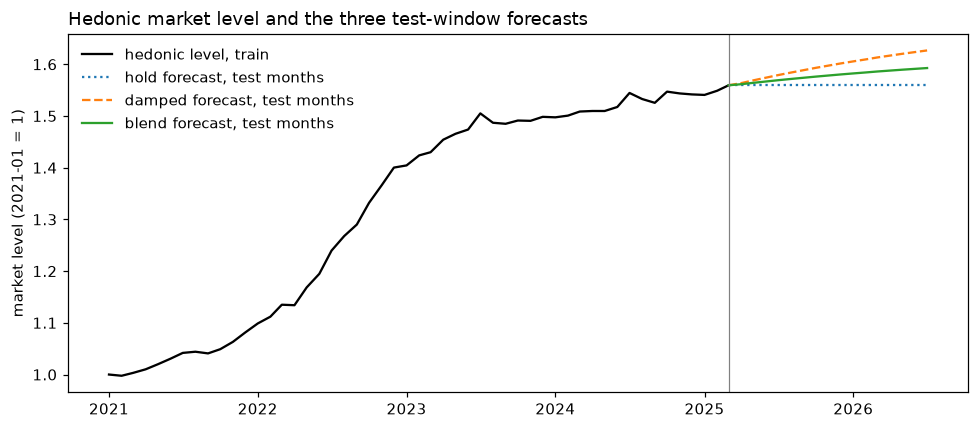

In [10]:
full_level = hedonic_level(train)
fig, ax = plt.subplots(figsize=(9, 4))
to_date = lambda idx: pd.to_datetime([f"{2021 + m // 12}-{m % 12 + 1:02d}" for m in idx])
ax.plot(to_date(full_level.index), np.exp(full_level), color="black", label="hedonic level, train")
for method, style in [("hold", ":"), ("damped", "--"), ("blend", "-")]:
    fc = forecast_level(full_level, test["MONTH_INDEX"].to_numpy(), method).loc[full_level.index.max():]
    ax.plot(to_date(fc.index), np.exp(fc), style, label=f"{method} forecast, test months")
    print(f"{method:<6} level change, 2025-03 to 2026-07: {np.exp(fc.iloc[-1] - fc.iloc[0]) - 1:+.1%}")
ax.axvline(pd.Timestamp("2025-03"), color="grey", lw=0.8)
ax.set_ylabel("market level (2021-01 = 1)")
ax.set_title("Hedonic market level and the three test-window forecasts", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

- **The damped trend alone is unsafe.** It gains most in the climb (786.8 → 613.0 at 2022-06) but, from the
  2022-12 origin, right as the climb ended, it keeps extrapolating and over-predicts by 533 (RMSE 870.9, the worst
  of any arm at any origin). The progress report (slide 11) and the `macro-time-trend` branch tested only 2022-06 and 2023-11 and so never
  saw this case.
- **Hold is the same as `MONTH_INDEX`** (637.3 vs 638.6 mean). The split on its own buys nothing; any gain comes
  from the forecast.
- **Blend is best on both mean and worst case**: mean 593.6 vs 638.6, worst origin 690.0 vs 790.8. It beats
  `MONTH_INDEX` at 8 of 9 origins and loses only at 2022-12 (623.2 vs 609.4). On the four origins from 2023-03
  on, where the market is flat as it was in early 2025, it is 3 to 16 better.
- **Caveat:** the blend was added after seeing the three-origin result, and the nine origins share data. Treat
  the gain as "the blend is a safer bet than either extreme", not as a precise 45-point improvement.
- **For the test window:** the damped trend puts the level 4.3% higher by 2026-07 than at 2025-03; the blend
  puts it 2.1% higher.

Appendix C tunes on the blend.

## 5. Summary

- **The report's damped-trend result does not hold across cutoffs.** At its two cutoffs (2022-06, 2023-11) the
  damped trend is the best arm here too (613.0, 489.2), but from the 2022-12 origin it over-predicts by 533 (RMSE
  870.9), worse than holding the level (609.4).
- **A hold/damped blend is the safer level forecast:** mean RMSE 593.6 vs 638.6 for the frozen `MONTH_INDEX` and
  611.3 for the damped trend; worst origin 690.0 vs 790.8 and 870.9. It was chosen after seeing the results, so
  the size of the gain is optimistic.
- **`07`'s combined model and first submission use the damped trend**, as the report proposed. Whether to switch
  to the blend should be decided on the slide-8 folds once next step 1 (one validation scheme, logged) is in place.
- **Appendices:** `03`/`06` base columns + `DIST` beat `main.ipynb`'s on these origins by 2.6 to 4.8; LightGBM ≈
  HistGradientBoosting > random forest > Ridge; tuning buys under 2 RMSE and averaging the two boosters nothing.
  The level forecast, not the model, is where the error is.

## Appendix A. Base columns: `03`/`06` vs `main.ipynb`

| spec | numeric | categorical |
|---|---|---|
| `03/06` | `FLOOR_AREA_SQM`, `LEASE_COMMENCE_DATE`, `MONTH_INDEX` | `TOWN`, `FLAT_TYPE`, `FLAT_MODEL` |
| `main` | `FLAT_TYPE_ORD`, `FLAT_AGE`, `MONTH_INDEX` | `TOWN`, `FLAT_MODEL` |
| `main + BLOCK_STREET` | as `main`, plus the `BLOCK_STREET` premium | as `main` |

`main.ipynb` has no time column; `MONTH_INDEX` is added to it per `01_eda_train` §7.8. Each spec is scored with and
without `DIST`, on LightGBM, across the three folds.

In [11]:
SPEC_MAIN = {"num": ["FLAT_TYPE_ORD", "FLAT_AGE", "MONTH_INDEX"], "cat": ["TOWN", "FLAT_MODEL"]}
SPEC_MAIN_BLOCK = {**SPEC_MAIN, "block_premium": True}
BASE_SPECS = {"03/06": SPEC_0306, "main": SPEC_MAIN, "main + BLOCK_STREET": SPEC_MAIN_BLOCK}

base_rows = []
for name, spec in BASE_SPECS.items():
    base_rows += evaluate("LightGBM", name, spec)
    base_rows += evaluate("LightGBM", f"{name} + DIST", with_dist(spec))
base_results = pd.DataFrame(base_rows)

base_table = base_results.pivot(index="spec", columns="origin", values=["rmse", "bias"])
base_table[("rmse", "mean")] = base_results.groupby("spec")["rmse"].mean()
base_table.sort_values(("rmse", "mean"))

rmse                    bias                   rmse
origin                     2021-12 2022-11 2023-11 2021-12 2022-11 2023-11   mean
spec                                                                             
03/06 + DIST                738.14  639.77  493.90 -417.58 -200.74  -43.98 623.93
main + BLOCK_STREET + DIST  745.32  638.07  493.61 -425.17 -204.60  -48.60 625.67
main + BLOCK_STREET         744.20  636.95  497.70 -420.94 -194.51  -43.90 626.28
main + DIST                 742.44  642.03  495.23 -422.07 -206.39  -50.43 626.57
03/06                       741.86  640.13  500.61 -417.07 -194.48  -42.73 627.53
main                        744.26  645.16  507.48 -418.42 -196.26  -50.24 632.30

In [12]:
dist_specs = [f"{name} + DIST" for name in BASE_SPECS]
best_base = base_results[base_results["spec"].isin(dist_specs)].groupby("spec")["rmse"].mean().idxmin()
print("best spec on mean RMSE:", best_base, "| used in section 4:", BEST_BASE)
print("  numeric    :", BEST_SPEC["num"] + (["BLOCK_PREMIUM"] if BEST_SPEC.get("block_premium") else []))
print("  categorical:", BEST_SPEC["cat"])

best spec on mean RMSE: 03/06 + DIST | used in section 4: 03/06 + DIST
  numeric    : ['FLOOR_AREA_SQM', 'LEASE_COMMENCE_DATE', 'MONTH_INDEX', 'MAX_FLOOR', 'primary_within_2km', 'mrt_within_2km', 'primary_nearest_km', 'mrt_nearest_km', 'secondary_within_1km', 'mrt_interchange_within_1km', 'mrt_interchange_nearest_km', 'malls_within_1km', 'malls_nearest_km', 'hawker_within_1km', 'hawker_nearest_km', 'dist_to_cbd_km']
  categorical: ['TOWN', 'FLAT_TYPE', 'FLAT_MODEL']


- **The spec matters far less than the fold.** All six specs sit within 9 of each other on mean RMSE; the market
  regime moves error by ~250 between folds.
- **`03/06 + DIST` is best** on mean RMSE (623.9). On the plateau fold it ties `main + BLOCK_STREET + DIST`
  (493.9 vs 493.6).
- **`DIST` helps on every fold:** 741.9 → 738.1, 640.1 → 639.8, 500.6 → 493.9. The plateau-fold gain (6.7) matches
  `06`'s +6.79 on a similar split; on the 2022-11 fold it is almost nothing.
- **`main.ipynb`'s column drops cost a little with trees:** 632.3 vs 627.5 without `DIST`, 626.6 vs 623.9 with it.
  Its ablation used a two-feature linear regression, where floor area and flat type are interchangeable; a tree
  uses both.
- **The `BLOCK_STREET` premium is redundant once `DIST` is in:** it improves `main` by 6.0 on its own but adds 0.9
  on top of `DIST`. Block coordinates already carry most of what the block identity says. Not kept.

## Appendix B. Model comparison

`BEST_SPEC`, four model families, the three origins.

In [13]:
MODELS = ["Ridge", "Random forest", "HistGradientBoosting", "LightGBM"]
model_results = pd.DataFrame([row for model in MODELS for row in evaluate(model, BEST_BASE, BEST_SPEC)])

model_table = model_results.pivot(index="model", columns="origin", values=["rmse", "bias"])
model_table[("rmse", "mean")] = model_results.groupby("model")["rmse"].mean()
model_table[("mae", "mean")] = model_results.groupby("model")["mae"].mean()
model_table.sort_values(("rmse", "mean"))

rmse                    bias                   rmse    mae
origin               2021-12 2022-11 2023-11 2021-12 2022-11 2023-11   mean   mean
model                                                                             
LightGBM              738.14  639.77  493.90 -417.58 -200.74  -43.98 623.93 488.44
HistGradientBoosting  744.24  637.20  494.93 -425.61 -203.18  -42.01 625.46 489.87
Random forest         755.01  660.12  509.39 -441.02 -226.17  -44.03 641.51 501.46
Ridge                 665.40  629.16  661.17 -312.69  -87.43  395.87 651.91 506.70

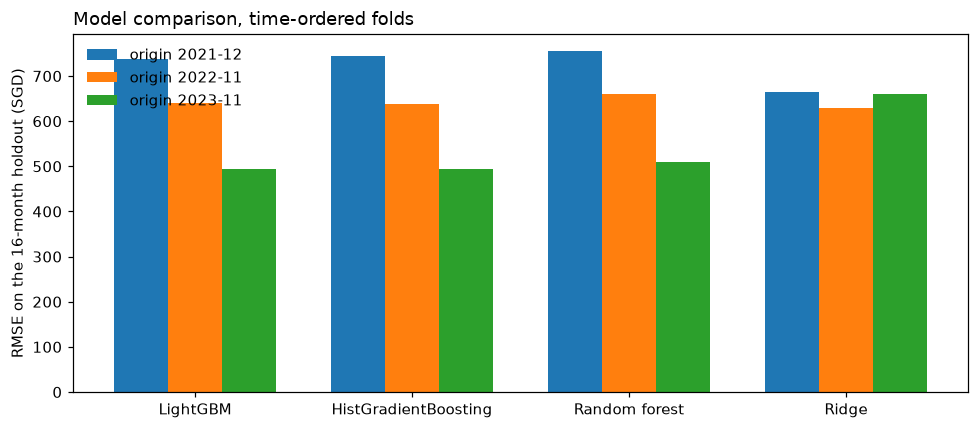

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
order = model_results.groupby("model")["rmse"].mean().sort_values().index
width = 0.25
for i, origin in enumerate(ORIGINS):
    vals = model_results[model_results["origin"] == origin].set_index("model").loc[order, "rmse"]
    ax.bar(np.arange(len(order)) + (i - 1) * width, vals, width=width, label=f"origin {origin}")
ax.set_xticks(np.arange(len(order)), order)
ax.set_ylabel("RMSE on the 16-month holdout (SGD)")
ax.set_title("Model comparison, time-ordered folds", loc="left")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

- **LightGBM is best** on mean RMSE (623.9) and on the plateau fold (493.9). HistGradientBoosting is within 1.5,
  effectively a tie: one seed, no tuning.
- **Random forest** is worse on every fold (+17.6 on mean).
- **Ridge is best while the market grows and worst once it stops.** A linear `MONTH_INDEX` extends the trend: it
  wins the 2021-12 fold (665 vs 738, bias −313 vs −418) and loses the plateau fold by 167 (bias +396). The trees
  hold the last level instead: large under-prediction in the growth years, near-zero bias on the plateau. Same
  behaviour as `01_eda_train` §7.6.
- No model choice here moves error as much as the level assumption does.

## Appendix C. Tuning and averaging

LightGBM and HistGradientBoosting tied in Appendix B, both on one untuned configuration. Each gets its default
plus 16 random draws, scored on the nine origins with the blend level. Random forest and Ridge are not tuned:
Appendix B put them 18 and 28 behind on mean RMSE.

In [15]:
LEVEL_METHOD = "blend"
PREMIUM_SPEC = premium_spec(BEST_SPEC)

# The level and the rent / level target depend only on the fold, so build them once.
level_folds = []
for origin, f, v in time_folds(train, WIDE_ORIGINS):
    s_fit, s_val = level_scales(f, v, LEVEL_METHOD)
    level_folds.append((origin, f.assign(**{TARGET: f[TARGET] / s_fit}), v, s_val))


def fold_predictions(model, params):
    return [fit_predict(model, PREMIUM_SPEC, f, v, params) * s for _, f, v, s in level_folds]


def fold_rmse(preds):
    return [score(v[TARGET].to_numpy(), p)["rmse"] for p, (_, _, v, _) in zip(preds, level_folds)]


rng = np.random.default_rng(SEED)
SEARCH = {
    "LightGBM": (LGB_PARAMS, lambda: {
        "n_estimators": int(rng.choice([300, 600, 1200])), "learning_rate": float(rng.choice([0.02, 0.05, 0.1])),
        "num_leaves": int(rng.choice([15, 31, 63, 127, 255])), "min_child_samples": int(rng.choice([10, 20, 50, 100])),
        "subsample": float(rng.choice([0.7, 0.85, 1.0])), "subsample_freq": 1,
        "colsample_bytree": float(rng.choice([0.6, 0.8, 1.0])), "reg_lambda": float(rng.choice([0.0, 1.0, 10.0])),
    }),
    "HistGradientBoosting": ({}, lambda: {
        "max_iter": int(rng.choice([300, 600, 1000])), "learning_rate": float(rng.choice([0.03, 0.05, 0.1])),
        "max_leaf_nodes": int(rng.choice([15, 31, 63, 127])), "min_samples_leaf": int(rng.choice([10, 20, 50, 100])),
        "l2_regularization": float(rng.choice([0.0, 1.0, 10.0])), "max_features": float(rng.choice([0.6, 0.8, 1.0])),
    }),
}
N_DRAWS = 16

search_rows, fold_preds = [], {}
for model, (default, draw) in SEARCH.items():
    for i, params in enumerate([default] + [draw() for _ in range(N_DRAWS)]):
        preds = fold_predictions(model, params)
        s = fold_rmse(preds)
        search_rows.append({"model": model, "draw": "default" if i == 0 else i, "rmse_mean": np.mean(s),
                            "rmse_worst": max(s), "params": params})
        fold_preds[(model, i)] = preds
search = pd.DataFrame(search_rows)
search.sort_values(["model", "rmse_mean"]).groupby("model").head(4)[["model", "draw", "rmse_mean", "rmse_worst", "params"]]

,model,draw,rmse_mean,rmse_worst,params
21,HistGradientBoosting,4,594.02,691.01,"{'max_iter': 1000, 'learning_rate': 0.1, 'max_..."
33,HistGradientBoosting,16,594.27,691.32,"{'max_iter': 300, 'learning_rate': 0.03, 'max_..."
29,HistGradientBoosting,12,594.33,691.11,"{'max_iter': 300, 'learning_rate': 0.1, 'max_l..."
28,HistGradientBoosting,11,594.35,691.19,"{'max_iter': 1000, 'learning_rate': 0.1, 'max_..."
2,LightGBM,2,591.91,689.24,"{'n_estimators': 300, 'learning_rate': 0.02, '..."
12,LightGBM,12,592.42,689.36,"{'n_estimators': 1200, 'learning_rate': 0.05, ..."
8,LightGBM,8,592.52,689.35,"{'n_estimators': 600, 'learning_rate': 0.1, 'n..."
4,LightGBM,4,592.73,689.33,"{'n_estimators': 1200, 'learning_rate': 0.1, '..."


In [16]:
best = search.loc[search.groupby("model")["rmse_mean"].idxmin()].set_index("model")
BEST_PARAMS = best["params"].to_dict()
best_draw = {m: 0 if d == "default" else d for m, d in best["draw"].items()}

per_fold = {f"{m} default": fold_rmse(fold_preds[(m, 0)]) for m in SEARCH}
per_fold.update({f"{m} tuned": fold_rmse(fold_preds[(m, best_draw[m])]) for m in SEARCH})
ensemble_preds = [(a + b) / 2 for a, b in zip(fold_preds[("LightGBM", best_draw["LightGBM"])],
                                             fold_preds[("HistGradientBoosting", best_draw["HistGradientBoosting"])])]
per_fold["average of the two tuned"] = fold_rmse(ensemble_preds)

tuning_table = pd.DataFrame(per_fold, index=WIDE_ORIGINS).T
tuning_table["mean"] = tuning_table.mean(axis=1)
tuning_table["worst"] = tuning_table[WIDE_ORIGINS].max(axis=1)
tuning_table.sort_values("mean")

,2021-12,2022-03,2022-06,2022-09,2022-12,2023-03,2023-06,2023-09,2023-11,mean,worst
LightGBM tuned,689.24,657.07,666.42,614.04,621.68,558.99,529.45,503.43,486.90,591.91,689.24
average of the two tuned,689.75,657.81,666.89,614.51,621.75,559.43,529.90,504.16,487.20,592.38,689.75
LightGBM default,690.00,657.98,666.91,615.27,623.21,561.50,531.73,506.19,489.75,593.62,690.00
HistGradientBoosting tuned,691.01,659.59,668.37,616.12,623.08,561.22,531.94,506.23,488.65,594.02,691.01
HistGradientBoosting default,691.35,659.99,669.20,617.46,624.55,563.56,533.43,508.20,491.86,595.51,691.35


- **Tuning buys under 2 RMSE:** LightGBM 593.6 → 591.9, HistGradientBoosting 595.5 → 594.0. That is the best of
  17 draws on the same folds used to pick it, so part of even that is selection luck.
- **Averaging the two does not help** (592.4, between the two). Their errors are almost the same at every
  origin: the level forecast dominates both, and it is shared.
- **Model settings are not where the error is.** The spread across origins (487 to 689) is a hundred times the
  spread across configurations. The next gain, if any, is in the level.